# Downsampling code test

In [1]:
joints_to_use = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14, 16, 17, 18, 19, 20, 21]

### Import code

In [2]:
import sys
if '../' not in sys.path:
    sys.path.append('../')

### Plotting functions

In [3]:
import numpy as np
from matplotlib import pyplot as plt
from hmp_utils.motion.mocap_processor import load_mocap, DownsampleMethod

def superimpose_plots_mocap(mocap_filepath, joint_id_to_plot, aa_element_to_plot, 
                            joints_to_use, framerates_to_plot, fig_opts):
    """superimposed graphs"""
    
    fig, ax = plt.subplots(**fig_opts)

    for framerate in framerates_to_plot:
        mocap_data = load_mocap(mocap_filepath, joints_to_use, framerate)
        assert mocap_data is not None

        x_axis = np.arange(mocap_data.rots.shape[0])
        x_axis = x_axis / framerate

        ax.plot(x_axis, mocap_data.rots[:, joint_id_to_plot, aa_element_to_plot], label=f'{framerate} fps',
                linewidth=1)

        plt.plot()
        
    ax.legend()
    plt.grid()
    plt.show()

def subplot_mocap(mocap_filepath, joint_id_to_plot, aa_element_to_plot, joints_to_use, framerates_to_plot, fig_opts):
    """adjacent graphs"""
    fig, axs = plt.subplots(len(framerates_to_plot), 1, sharex=True, **fig_opts)

    for i, framerate in enumerate(framerates_to_plot):
        mocap_data = load_mocap(mocap_filepath, joints_to_use, framerate)
        assert mocap_data is not None
        
        x_axis = np.arange(mocap_data.rots.shape[0])
        x_axis = x_axis / framerate

        axs[i].plot(x_axis, mocap_data.rots[:, joint_id_to_plot, aa_element_to_plot])
        axs[i].set_title(f'{framerate} fps')
        axs[i].grid(True)

        plt.plot()
        
    plt.show()



### View downsampling effects

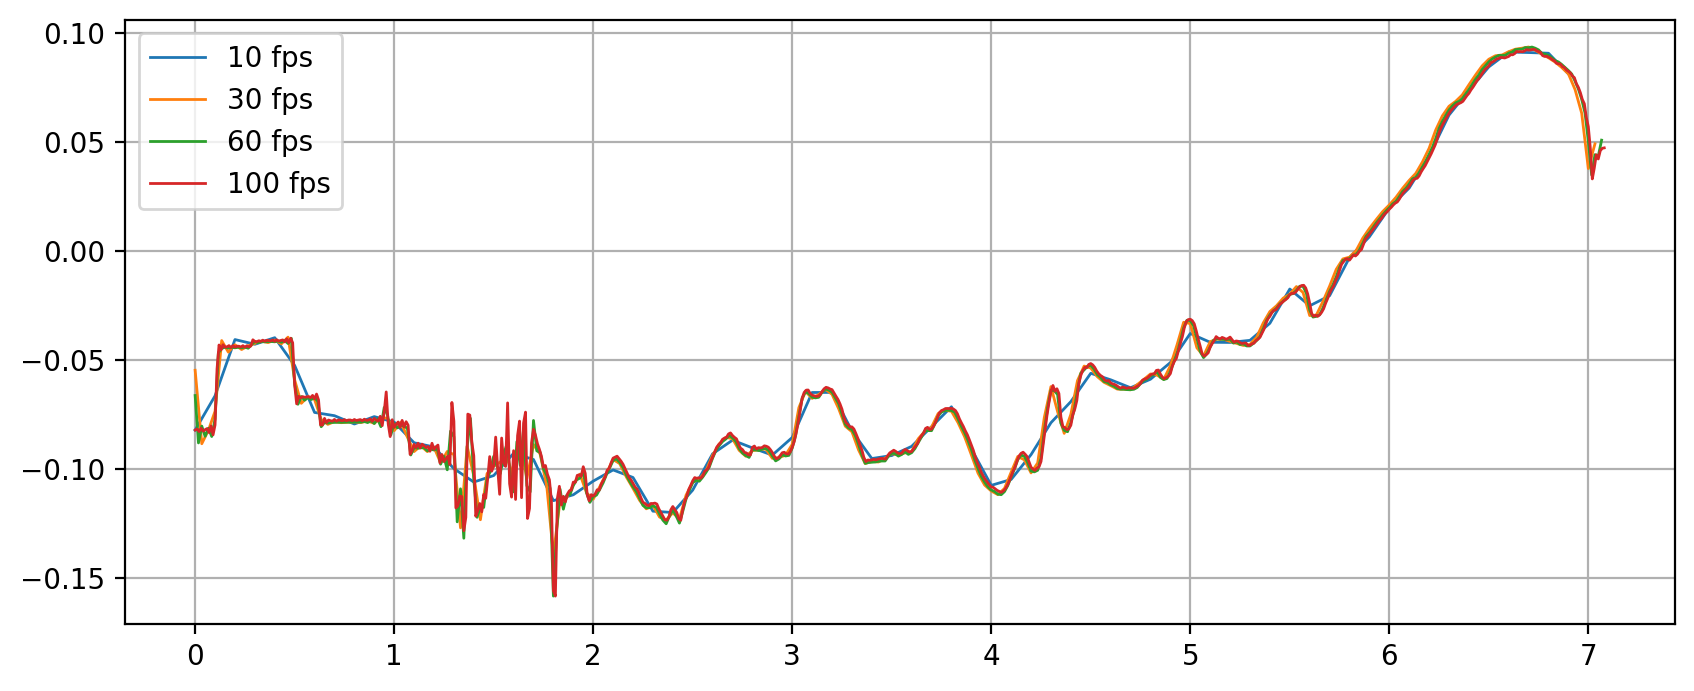

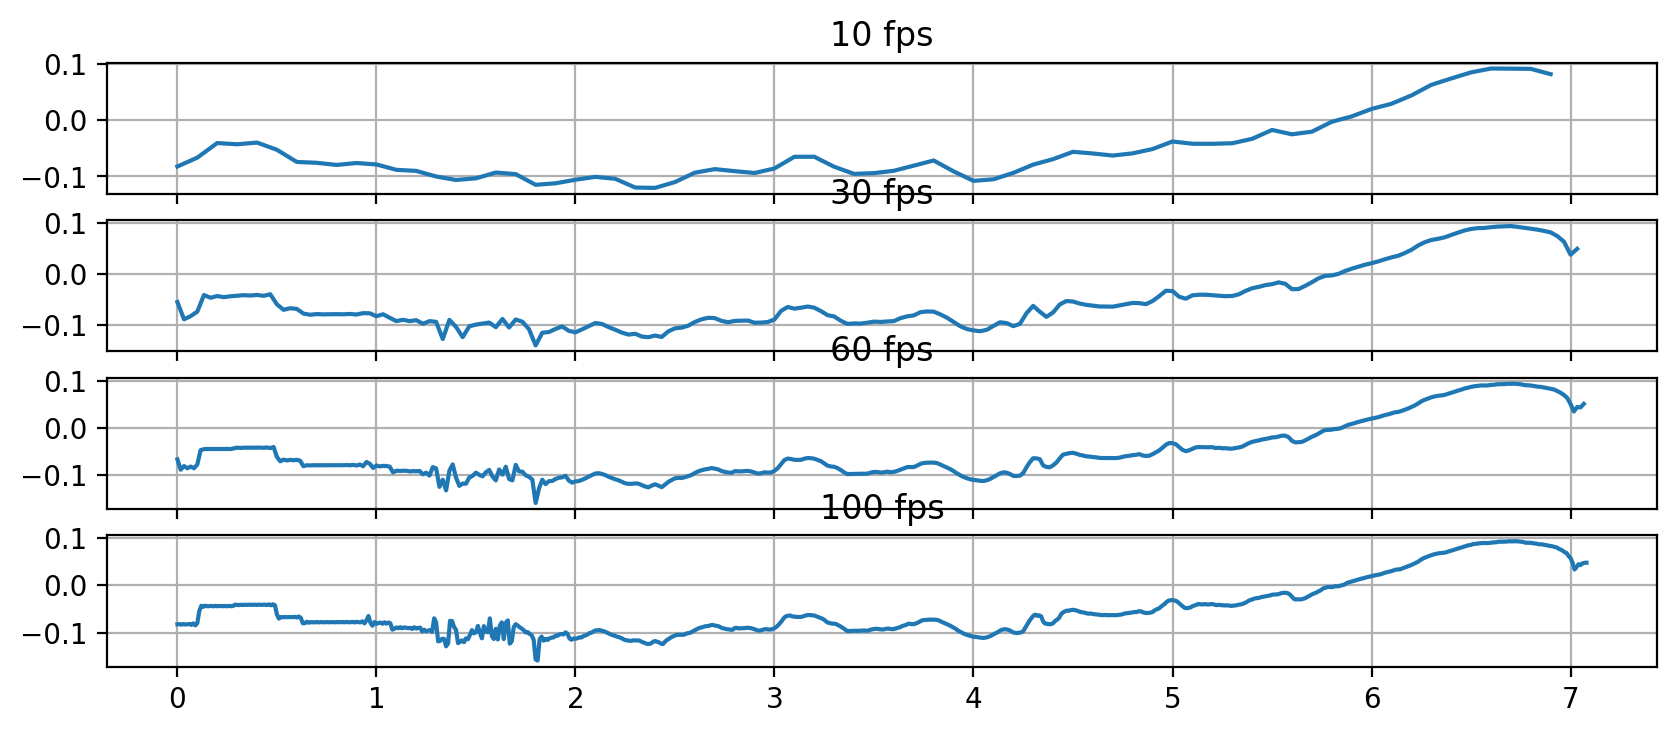

In [4]:
# 60 Hz test file
# mocap_filepath = '/tf/app/frabors-code/AMASS_DATASET/SSMsynced/SSM_synced/20160330_03333/ATU_001_poses.npz'
# framerates_to_plot = [10, 30, 60]

# 100 Hz test file
mocap_filepath = '/tf/app/frabors-code/AMASS_DATASET/EKUT/125/SLP101_poses.npz' # 100 Hz
framerates_to_plot = [10, 30, 60, 100]


# plot params
joint_id_to_plot = 10
aa_element_to_plot = 0
fig_opts = {'dpi':200,
            'figsize':(10,4)}

superimpose_plots_mocap(mocap_filepath, joint_id_to_plot, aa_element_to_plot, 
                        joints_to_use, framerates_to_plot, fig_opts)
subplot_mocap(mocap_filepath, joint_id_to_plot, aa_element_to_plot, 
              joints_to_use, framerates_to_plot, fig_opts)


## Slerp vs Decimation / Resampling

is slerp


ValueError: cannot reshape array of size 13471 into shape (709,3)

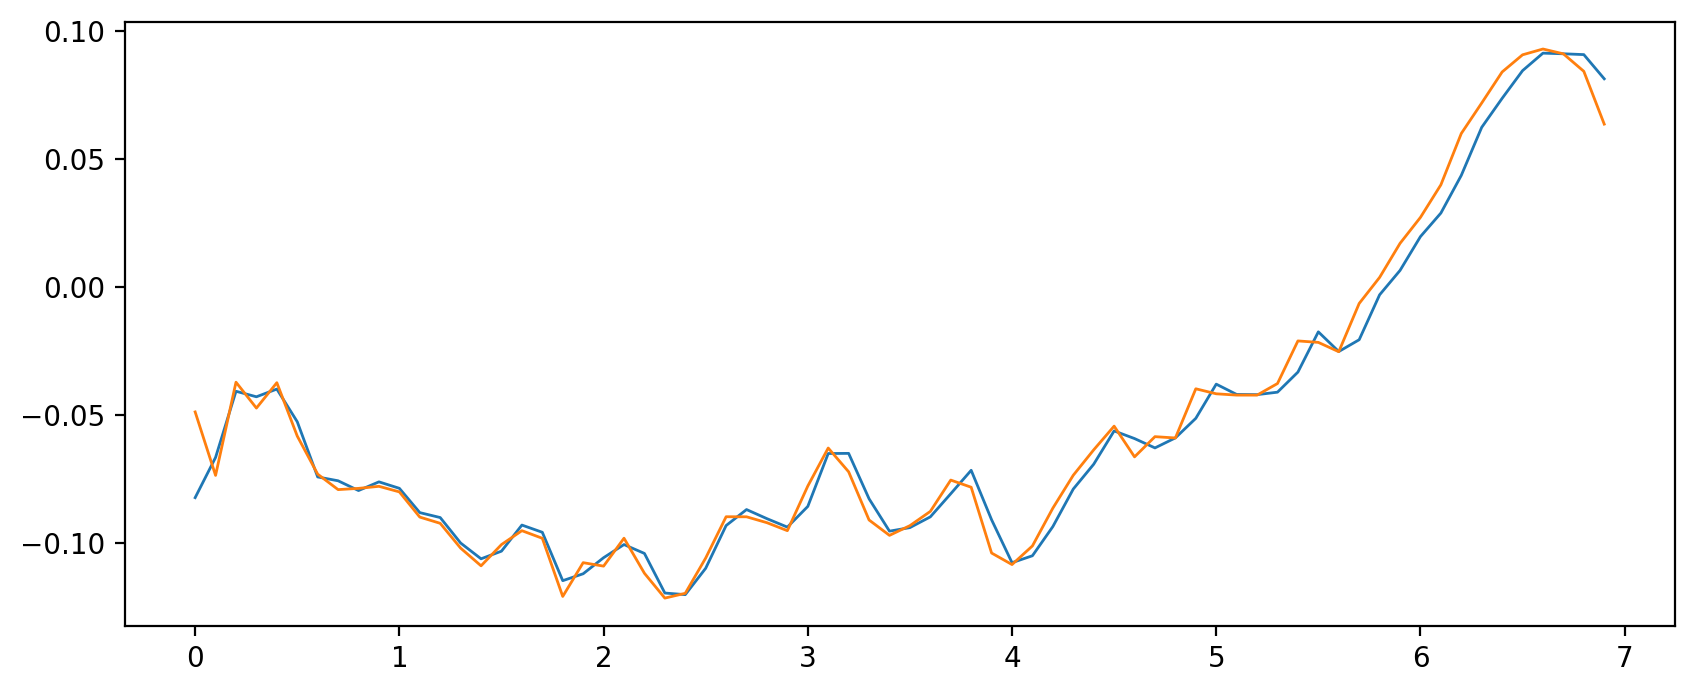

In [5]:
fig, ax = plt.subplots(**fig_opts)
target_framerate = 10
downsample_methods = [DownsampleMethod.decimate, DownsampleMethod.resample, DownsampleMethod.slerp]
downsample_methods_names = ['decimate', 'resample', 'slerp']

for idx, method in enumerate(downsample_methods):
    mocap_data = load_mocap(mocap_filepath, joints_to_use, target_framerate, 
                            target_downsampling_method=method)
    assert mocap_data is not None

    x_axis = np.arange(mocap_data.rots.shape[0])
    x_axis = x_axis / target_framerate

    ax.plot(x_axis, mocap_data.rots[:, joint_id_to_plot, aa_element_to_plot], 
            label=f'{downsample_methods_names[idx]}',
            linewidth=1)

    plt.plot()
    
ax.legend()
plt.grid()
plt.show()